# Домашнее задание 8

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)


In [2]:
COLUMNS = [
    "surgery", "age", "hospital_number", "rectal_temperature", "pulse",
    "respiratory_rate", "temperature_of_extremities", "peripheral_pulse",
    "mucous_membranes", "capillary_refill_time", "pain", "peristalsis",
    "abdominal_distension", "nasogastric_tube", "nasogastric_reflux",
    "nasogastric_reflux_ph", "rectal_examination", "abdomen",
    "packed_cell_volume", "total_protein", "abdominocentesis_appearance",
    "abdominocentesis_total_protein", "outcome", "surgical_lesion",
    "type_of_lesion_1", "type_of_lesion_2", "type_of_lesion_3", "cp_data",
]

NUMERIC = [
    "rectal_temperature", "pulse", "respiratory_rate",
    "packed_cell_volume", "total_protein",
]

CATEGORICAL = ["surgery", "age", "outcome"]


def load_horses(file_path):
    return pd.read_csv(file_path, header=None, names=COLUMNS, na_values="?")


def numeric_metrics(data, columns):
    return pd.DataFrame({
        "n": data[columns].count(),
        "пропуски": data[columns].isna().sum(),
        "среднее": data[columns].mean().round(2),
        "медиана": data[columns].median().round(2),
        "мода": [data[c].mode().iloc[0] if not data[c].mode().empty else float("nan")
                 for c in columns],
        "std": data[columns].std().round(2),
        "min": data[columns].min(),
        "Q1": data[columns].quantile(0.25),
        "Q3": data[columns].quantile(0.75),
        "max": data[columns].max(),
    }, index=columns)


def categorical_metrics(data, column):
    counts = data[column].value_counts(dropna=False).sort_index()
    shares = data[column].value_counts(normalize=True, dropna=False).sort_index().round(3)
    mode = data[column].mode().iloc[0] if not data[column].mode().empty else float("nan")
    return pd.DataFrame({"частота": counts, "доля": shares}), mode


def iqr_bounds(series):
    first_quartile = series.quantile(0.25)
    third_quartile = series.quantile(0.75)
    spread = third_quartile - first_quartile
    return first_quartile - 1.5 * spread, third_quartile + 1.5 * spread


def find_outliers(data, column):
    series = data[column].dropna()
    lower, upper = iqr_bounds(series)
    return series[(series < lower) | (series > upper)]


def outliers_table(data, columns):
    rows = []
    for column in columns:
        series = data[column].dropna()
        lower, upper = iqr_bounds(series)
        outliers = find_outliers(data, column)
        rows.append({
            "столбец": column,
            "Q1": round(series.quantile(0.25), 2),
            "Q3": round(series.quantile(0.75), 2),
            "нижняя граница": round(lower, 2),
            "верхняя граница": round(upper, 2),
            "выбросов": len(outliers),
            "доля, %": round(100 * len(outliers) / len(series), 1),
            "min": series.min(),
            "max": series.max(),
        })
    return pd.DataFrame(rows).set_index("столбец")


def normalize_protein_units(data, column="total_protein", threshold=20, factor=10):
    result = data.copy()
    mask = result[column] > threshold
    result.loc[mask, column] = result.loc[mask, column] / factor
    return result, int(mask.sum())


def missing_table(data, columns):
    return pd.DataFrame({
        "пропусков": data[columns].isna().sum(),
        "доля, %": (100 * data[columns].isna().mean()).round(1),
    })


def fill_numeric_median(data, columns):
    result = data.copy()
    for column in columns:
        result[column] = result[column].fillna(result[column].median())
    return result


def fill_categorical_mode(data, columns):
    result = data.copy()
    for column in columns:
        if not result[column].mode().empty:
            result[column] = result[column].fillna(result[column].mode().iloc[0])
    return result


def plot_protein(before, after, column="total_protein"):
    figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    before[column].dropna().plot(kind="hist", bins=20, ax=axes[0], color="indianred")
    axes[0].set_title("До приведения единиц")
    axes[0].set_xlabel(column)
    after[column].dropna().plot(kind="hist", bins=20, ax=axes[1], color="seagreen")
    axes[1].set_title("После приведения единиц")
    axes[1].set_xlabel("total_protein, г/дл")
    figure.tight_layout()
    return figure


horses = load_horses("horse_data.csv")


## Задание 1. Восемь столбцов

In [3]:
print(f"Строк: {len(horses)}, столбцов: {horses.shape[1]}")

print("\n=== Числовые столбцы: базовые метрики ===")
print(numeric_metrics(horses, NUMERIC).to_string())

print("\n=== Категориальные столбцы ===")
for column in CATEGORICAL:
    table, mode = categorical_metrics(horses, column)
    print(f"\n--- {column} (мода = {mode}) ---")
    print(table.to_string())


Строк: 300, столбцов: 28

=== Числовые столбцы: базовые метрики ===
                      n  пропуски  среднее  медиана  мода    std   min    Q1    Q3    max
rectal_temperature  240        60    38.17     38.2  38.0   0.73  35.4  37.8  38.5   40.8
pulse               276        24    71.91     64.0  48.0  28.63  30.0  48.0  88.0  184.0
respiratory_rate    242        58    30.42     24.5  20.0  17.64   8.0  18.5  36.0   96.0
packed_cell_volume  271        29    46.30     45.0  37.0  10.42  23.0  38.0  52.0   75.0
total_protein       267        33    24.46      7.5   6.5  27.48   3.3   6.5  57.0   89.0

=== Категориальные столбцы ===

--- surgery (мода = 1.0) ---
         частота   доля
surgery                
1.0          180  0.600
2.0          119  0.397
NaN            1  0.003

--- age (мода = 1) ---
     частота  доля
age               
1        276  0.92
9         24  0.08

--- outcome (мода = 1.0) ---
         частота   доля
outcome                
1.0          178  0.593
2.0     

## Задание 2. Выбросы

In [4]:
print("=== Сводка по выбросам ===")
print(outliers_table(horses, NUMERIC).to_string())

print("\n=== Сами значения выбросов ===")
for column in NUMERIC:
    values = sorted(find_outliers(horses, column).tolist())
    print(f"{column}: {values}")


=== Сводка по выбросам ===
                      Q1    Q3  нижняя граница  верхняя граница  выбросов  доля, %   min    max
столбец                                                                                        
rectal_temperature  37.8  38.5           36.75            39.55        14      5.8  35.4   40.8
pulse               48.0  88.0          -12.00           148.00         5      1.8  30.0  184.0
respiratory_rate    18.5  36.0           -7.75            62.25        17      7.0   8.0   96.0
packed_cell_volume  38.0  52.0           17.00            73.00         3      1.1  23.0   75.0
total_protein        6.5  57.0          -69.25           132.75         0      0.0   3.3   89.0

=== Сами значения выбросов ===
rectal_temperature: [35.4, 36.0, 36.1, 36.4, 36.5, 36.5, 36.6, 39.6, 39.7, 39.9, 40.0, 40.3, 40.3, 40.8]
pulse: [150.0, 150.0, 160.0, 164.0, 184.0]
respiratory_rate: [66.0, 68.0, 68.0, 68.0, 70.0, 70.0, 72.0, 80.0, 80.0, 80.0, 84.0, 84.0, 88.0, 90.0, 90.0, 96.0, 96.0]


Приведено значений: 79

Было:
count    267.00
mean      24.46
std       27.48
min        3.30
25%        6.50
50%        7.50
75%       57.00
max       89.00

Стало:
count    267.00
mean       6.85
std        1.09
min        3.30
25%        6.20
50%        6.70
75%        7.50
max       13.00

Выбросов после приведения: 5


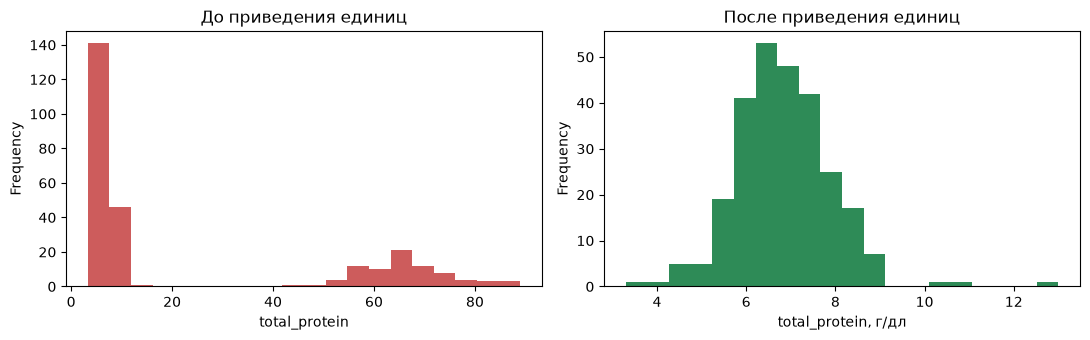

In [5]:
fixed, changed = normalize_protein_units(horses)

print(f"Приведено значений: {changed}")
print("\nБыло:")
print(horses["total_protein"].describe().round(2).to_string())
print("\nСтало:")
print(fixed["total_protein"].describe().round(2).to_string())
print("\nВыбросов после приведения:", len(find_outliers(fixed, "total_protein")))

plot_protein(horses, fixed)


## Задание 3. Пропуски

In [6]:
columns = NUMERIC + CATEGORICAL
table = missing_table(horses, columns)
table["выбросов"] = [len(find_outliers(horses, c)) for c in table.index]
print(table.to_string())
print(f"\nВсего строк: {len(horses)}")


                    пропусков  доля, %  выбросов
rectal_temperature         60     20.0        14
pulse                      24      8.0         5
respiratory_rate           58     19.3        17
packed_cell_volume         29      9.7         3
total_protein              33     11.0         0
surgery                     1      0.3         0
age                         0      0.0        24
outcome                     1      0.3         0

Всего строк: 300


In [7]:
normalized, _ = normalize_protein_units(horses)
trimmed = normalized.dropna(subset=CATEGORICAL).copy()
clean = fill_numeric_median(trimmed, NUMERIC)[NUMERIC + CATEGORICAL]

print("Форма датафрейма:", clean.shape)
print("Пропусков всего:", int(clean.isna().sum().sum()))
print("\nПропуски по столбцам:")
print(clean.isna().sum().to_string())
print("\nПервые 5 строк:")
print(clean.head().to_string())


Форма датафрейма: (299, 8)
Пропусков всего: 0

Пропуски по столбцам:
rectal_temperature    0
pulse                 0
respiratory_rate      0
packed_cell_volume    0
total_protein         0
surgery               0
age                   0
outcome               0

Первые 5 строк:
   rectal_temperature  pulse  respiratory_rate  packed_cell_volume  total_protein  surgery  age  outcome
0                38.5   66.0              28.0                45.0            8.4      2.0    1      2.0
1                39.2   88.0              20.0                50.0            8.5      1.0    1      3.0
2                38.3   40.0              24.0                33.0            6.7      2.0    1      1.0
3                39.1  164.0              84.0                48.0            7.2      1.0    9      2.0
4                37.3  104.0              35.0                74.0            7.4      2.0    1      2.0


## Дополнительная часть. Все 28 столбцов

In [8]:
CONTINUOUS = [
    "rectal_temperature", "pulse", "respiratory_rate", "packed_cell_volume",
    "total_protein", "nasogastric_reflux_ph", "abdominocentesis_total_protein",
    "hospital_number", "temperature_of_extremities", "peripheral_pulse",
    "mucous_membranes", "capillary_refill_time", "pain", "peristalsis",
    "abdominal_distension", "nasogastric_tube", "nasogastric_reflux",
    "rectal_examination", "abdomen", "abdominocentesis_appearance",
]

CATEGORICAL_ALL = [
    "surgery", "age", "outcome", "surgical_lesion", "cp_data",
    "type_of_lesion_1", "type_of_lesion_2", "type_of_lesion_3",
]

print("=== Числовые столбцы: метрики ===")
print(numeric_metrics(horses, CONTINUOUS).to_string())

print("\n=== Выбросы по всем числовым столбцам ===")
print(outliers_table(horses, CONTINUOUS).to_string())

print("\n=== Пропуски по всем 28 столбцам ===")
table = missing_table(horses, COLUMNS)
print(table.sort_values("пропусков", ascending=False).to_string())

print(f"\nВсего пропусков: {int(horses.isna().sum().sum())} "
      f"из {horses.shape[0] * horses.shape[1]} ячеек")


=== Числовые столбцы: метрики ===
                                  n  пропуски     среднее    медиана      мода         std       min        Q1        Q3        max
rectal_temperature              240        60       38.17      38.20      38.0        0.73      35.4      37.8      38.5       40.8
pulse                           276        24       71.91      64.00      48.0       28.63      30.0      48.0      88.0      184.0
respiratory_rate                242        58       30.42      24.50      20.0       17.64       8.0      18.5      36.0       96.0
packed_cell_volume              271        29       46.30      45.00      37.0       10.42      23.0      38.0      52.0       75.0
total_protein                   267        33       24.46       7.50       6.5       27.48       3.3       6.5      57.0       89.0
nasogastric_reflux_ph            53       247        4.71       5.00       2.0        1.98       1.0       3.0       6.5        7.5
abdominocentesis_total_protein  102       

In [9]:
normalized, _ = normalize_protein_units(horses)
trimmed = normalized.dropna(subset=["surgery", "outcome"]).copy()

share = trimmed.isna().mean()
dropped = [c for c in share.index if share[c] > 0.5]
trimmed = trimmed.drop(columns=dropped)

present_continuous = [c for c in CONTINUOUS if c in trimmed.columns]
present_categorical = [c for c in CATEGORICAL_ALL if c in trimmed.columns]

clean_full = fill_numeric_median(trimmed, present_continuous)
clean_full = fill_categorical_mode(clean_full, present_categorical)

print("Отброшено столбцов (пропусков > 50 %):")
for column in dropped:
    print("  -", column)
print(f"\nФорма: {clean_full.shape}")
print("Пропусков:", int(clean_full.isna().sum().sum()))
print("\nПервые 5 строк:")
print(clean_full.head().to_string())


Отброшено столбцов (пропусков > 50 %):
  - nasogastric_reflux_ph
  - abdominocentesis_appearance
  - abdominocentesis_total_protein

Форма: (299, 25)
Пропусков: 0

Первые 5 строк:
   surgery  age  hospital_number  rectal_temperature  pulse  respiratory_rate  temperature_of_extremities  peripheral_pulse  mucous_membranes  capillary_refill_time  pain  peristalsis  abdominal_distension  nasogastric_tube  nasogastric_reflux  rectal_examination  abdomen  packed_cell_volume  total_protein  outcome  surgical_lesion  type_of_lesion_1  type_of_lesion_2  type_of_lesion_3  cp_data
0      2.0    1           530101                38.5   66.0              28.0                         3.0               3.0               3.0                    2.0   5.0          4.0                   4.0               2.0                 1.0                 3.0      5.0                45.0            8.4      2.0                2             11300                 0                 0        2
1      1.0    1           